# 09 The shipped model on discharges nobody trained on: final evaluation

**Question.** How accurate is the shipped model on whole discharges that none of its networks was trained on, per parameter,
in mm and kA, and how far can that number be trusted?

**Recipe in two lines** (`analysis/ipp1_final.py`, recipe `cand`). A network on the 24 magnetic inputs plus 22 differences of neighbouring coils
(46 inputs, 256-256-128, Huber loss, 150 epochs), a ridge regression for `plasma_current`, and a second network trained only on limited-plasma rows
that answers `R_limiter` and `Z_limiter` when the first network predicts `is_limited > 0.5`. The reference is the plain baseline network of notebook 02.

**Protocol.** 30 of the 149 discharges were set aside before the final choice among four recipes (ids in `results/ipp1-locked-test-ids.txt`,
numpy seed 20261024). Every model here is trained on the other 119 discharges (the development set) and scored once on the 30, pooled over their rows.
Recipe choices used 5-fold cross-validation by discharge inside the development set. This notebook trains nothing: it reads the predictions that
`analysis/ipp1_final.py` cached in `out/ipp1-final-cache/` (made by `analysis/make_all.py`), recomputes every metric from them, and compares the result
with the numbers stored in `results/ipp1-final.md`. Three limits first, each repeated where it matters: (1) the 30 discharges are **easier**
than the development average; (2) they were set aside before the final choice but **not unseen by the idea**: the recipe ideas were tried on
cross-validation over all 149 discharges; (3) most numbers are one seed per model (the seed check in section 6 measures how much that matters).

In [1]:
import os, sys, re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next(p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists())
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C
import ipp1_final as F

RES = repo / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
KEY = {}
pd.set_option("display.width", 200)

def proto(text):
    print("\nProtocol:", text)

assert not F.SMOKE, "IPP1_FINAL_SMOKE is set: the cache would hold one-epoch networks"
print("raw data folder found:", C.DATA.exists(), "| cache of ipp1_final.py (out/ipp1-final-cache) found:", F.CACHE.exists())
RECS = ["base", "cand", "base_aug"]
need = ([f"locked_{r}.npz" for r in RECS] + [f"blocked_{r}.npz" for r in RECS] + [f"cv_{r}_{k}.npz" for r in RECS for k in range(5)])
missing = [n for n in need if not (F.CACHE / n).exists()]
assert not missing, f"{len(missing)} cached prediction files missing (e.g. {missing[:3]}): run analysis/make_all.py first"
print("cached predictions found:", len(need), "files")

raw data folder found: True | cache of ipp1_final.py (out/ipp1-final-cache) found: True
cached predictions found: 21 files


## 1. The 30 discharges and how they differ from the rest

The split is recomputed from the seed and compared with the stored id list, so the notebook cannot score a different set by accident.

In [2]:
(df, X, Y, G, M), XN = F.aligned_data()
J = {t: i for i, t in enumerate(C.TARGETS)}
lock, dev_idx, lock_idx = F.split(G)
txt = (RES / "ipp1-locked-test-ids.txt").read_text()
stored_ids = [int(v) for v in txt.split("locked discharge ids")[1].split(":", 1)[1].split()]
assert list(lock) == stored_ids and len(lock) == 30, "recomputed locked ids differ from results/ipp1-locked-test-ids.txt"
assert not set(G[dev_idx]) & set(G[lock_idx])
yl, ml, gl = Y[lock_idx], M[lock_idx], G[lock_idx]

def sign_of(g_rows, idx):
    # polarity of a discharge: the sign of its median plasma current
    return {g: np.sign(np.nanmedian(Y[idx][g_rows == g, 0])) for g in np.unique(g_rows)}
sl, sd = sign_of(gl, lock_idx), sign_of(G[dev_idx], dev_idx)
lim = Y[:, J["is_limited"]] > 0.5
tab = pd.DataFrame({
    "discharges": [len(np.unique(G[dev_idx])), len(lock)],
    "rows": [len(dev_idx), len(lock_idx)],
    "positive plasma current (discharges)": [sum(v > 0 for v in sd.values()), sum(v > 0 for v in sl.values())],
    "limited rows (share)": [lim[dev_idx].mean(), lim[lock_idx].mean()],
}, index=["development (training)", "locked test"])
print(tab.round(3).to_string())
KEY["locked_discharges"] = int(len(lock)); KEY["locked_rows"] = int(len(lock_idx))
KEY["positive_polarity"] = {"development": int(tab.iloc[0, 2]), "locked": int(tab.iloc[1, 2])}
proto("30 discharges drawn with numpy seed 20261024; the other 119 are the development set; rows counted as in the data; no model involved.")

                        discharges   rows  positive plasma current (discharges)  limited rows (share)
development (training)         119  34211                                    14                 0.452
locked test                     30   8761                                     2                 0.406

Protocol: 30 discharges drawn with numpy seed 20261024; the other 119 are the development set; rows counted as in the data; no model involved.


Only two of the 30 discharges have the reversed (positive) plasma current. In `results/ipp1-distribution.md` such discharges carry most of the
squared axis error, so a test set with few of them flatters the average. Section 3 measures how much easier this set is.

## 2. Result on the 30 discharges, per parameter

Mean absolute error (MAE) in the unit of the parameter (mm for positions, kA for the plasma current), median and 99th percentile over the
8,761 rows of the 30 discharges, for the shipped candidate and the baseline network, both trained on the 119 development discharges.

In [3]:
lk = F.assemble("locked", None, RECS)
for r in RECS:
    assert np.array_equal(lk[r]["idx"], lock_idx), f"cached locked predictions of {r} are not for the 30 locked discharges"
L = {r: {c: F.tstats(lk[r][c], yl, ml) for c in ("clean", "noisy")} for r in RECS}
rows = []
for t in C.TARGETS:
    c, b = L["cand"]["clean"][t], L["base"]["clean"][t]
    rows.append(dict(target=t, unit=c["unit"] or "-", rows=c["n"], cand_MAE=c["mae"], cand_median=c["median"], cand_p99=c["p99"],
                     base_MAE=b["mae"], cand_over_base=c["mae"] / b["mae"]))
main = pd.DataFrame(rows).set_index("target")
print(main.round(4).to_string())
KEY["locked_mae_cand"] = {t: round(L["cand"]["clean"][t]["mae"], 4) for t in F.HEADLINE}
KEY["locked_mae_base"] = {t: round(L["base"]["clean"][t]["mae"], 4) for t in F.HEADLINE}
KEY["is_limited_accuracy_locked"] = {"cand": round(float(L["cand"]["clean"]["is_limited"]["accuracy"]), 4),
                                    "base": round(float(L["base"]["clean"]["is_limited"]["accuracy"]), 4)}
print("\nis_limited accuracy: candidate %.4f, baseline %.4f" % (KEY["is_limited_accuracy_locked"]["cand"], KEY["is_limited_accuracy_locked"]["base"]))
proto("candidate and baseline each trained once (seed 0) on 119 development discharges, scored once on the 30 locked discharges, clean inputs, pooled over 8,761 rows.")

                    unit  rows  cand_MAE  cand_median  cand_p99  base_MAE  cand_over_base
target                                                                                   
plasma_current        kA  8760    0.0347       0.0258    0.1432    1.1986          0.0289
R_mag_axis            mm  8761    0.1331       0.0614    1.3931    0.3067          0.4339
Z_mag_axis            mm  8761    0.1721       0.0785    1.5931    0.3213          0.5354
elongation             -  8760    0.0028       0.0012    0.0333    0.0044          0.6313
triangularity          -  8760    0.0014       0.0008    0.0145    0.0022          0.6067
triangularity_upper    -  8760    0.0015       0.0012    0.0109    0.0026          0.5864
triangularity_lower    -  8760    0.0018       0.0008    0.0191    0.0030          0.6153
R_x_point             mm  5207    0.1153       0.0558    1.0101    0.1610          0.7161
Z_x_point             mm  5207    0.0969       0.0417    0.7156    0.1617          0.5989
R_strike_p

### Check against the stored report

The same numbers are in `results/ipp1-final.md` (printed with three significant digits). The notebook recomputes them from the cached predictions
and fails if they differ by more than the rounding, so the notebook and the report cannot drift apart.

In [4]:
def stored_mae(heading):
    lines = (RES / "ipp1-final.md").read_text().splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith(heading))
    out = {}
    for l in lines[i + 4:]:
        if not l.startswith("|"):
            break
        cells = [c.strip() for c in l.strip("|").split("|")]
        out[cells[0]] = float(cells[3])
    return out

rel = {}
for r, heading in (("cand", "### candidate, plain, clean inputs"), ("base", "### baseline MLP, clean inputs")):
    st = stored_mae(heading)
    for t in C.TARGETS:
        rel[(r, t)] = abs(L[r]["clean"][t]["mae"] - st[t]) / abs(st[t])
worst_key = max(rel, key=rel.get)
print(f"targets compared: {len(rel)} | largest relative difference to the report: {100 * rel[worst_key]:.2f} % ({worst_key[0]}, {worst_key[1]})")
if rel[worst_key] > 0.015:
    print("NOTE: the cache was rebuilt on this machine. Training is not bit for bit identical across machines and thread counts, so differences of the size of the "
          "seed noise (3 to 13 %, section 6) are expected; the numbers below then differ slightly from the report and from the text of the conclusions.")
assert rel[worst_key] < 0.5, "the cached predictions are far from the stored report: wrong cache or wrong split"
KEY["max_rel_diff_to_report_pct"] = round(100 * rel[worst_key], 2)
proto("recomputed from the cached predictions against the MAE column of results/ipp1-final.md (3 significant digits).")

targets compared: 32 | largest relative difference to the report: 0.32 % (cand, R_strike_point_2)

Protocol: recomputed from the cached predictions against the MAE column of results/ipp1-final.md (3 significant digits).


### How much does the number depend on which 30 discharges were drawn?

A cluster bootstrap resamples whole discharges (1,000 resamples) and gives a 95 % interval for each MAE and for the ratio candidate over baseline
on the same resamples. A ratio interval that stays below 1 means the candidate is better on every resample.

                 unit  cand_MAE  cand_lo  cand_hi  base_MAE  ratio  ratio_lo  ratio_hi
target                                                                                
plasma_current     kA     0.035    0.031    0.038     1.199  0.029     0.024     0.035
R_mag_axis         mm     0.133    0.099    0.177     0.307  0.434     0.381     0.485
Z_mag_axis         mm     0.172    0.128    0.223     0.321  0.535     0.472     0.602
R_x_point          mm     0.115    0.076    0.168     0.161  0.716     0.530     0.974
Z_x_point          mm     0.097    0.067    0.130     0.162  0.599     0.494     0.707
R_strike_point_1   mm     0.108    0.077    0.144     0.212  0.509     0.396     0.632
Z_strike_point_1   mm     0.046    0.034    0.061     0.099  0.465     0.399     0.542
R_strike_point_2   mm     0.136    0.084    0.205     0.212  0.640     0.432     0.937
Z_strike_point_2   mm     0.026    0.019    0.036     0.045  0.581     0.473     0.701
R_limiter          mm     4.549    3.302   

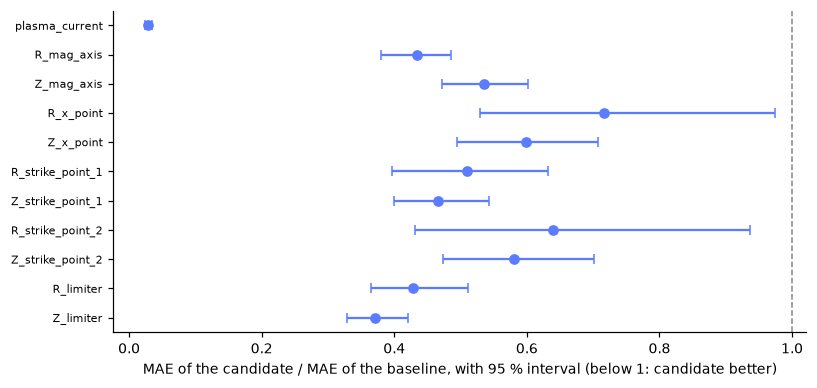

In [5]:
boot = F.bootstrap({"base": lk["base"]["clean"], "cand": lk["cand"]["clean"]}, yl, ml, gl, F.HEADLINE)
rows = []
for t in F.HEADLINE:
    c, b = boot["cand"][t], boot["base"][t]
    rows.append(dict(target=t, unit=F.UNIT[t][1], cand_MAE=c["mae"], cand_lo=c["mae_ci"][0], cand_hi=c["mae_ci"][1],
                     base_MAE=b["mae"], ratio=c["mae_ratio_vs_base"], ratio_lo=c["mae_ratio_ci"][0], ratio_hi=c["mae_ratio_ci"][1]))
bt = pd.DataFrame(rows).set_index("target")
print(bt.round(3).to_string())
KEY["bootstrap_ratio"] = {t: [round(bt.loc[t, "ratio"], 2), round(bt.loc[t, "ratio_lo"], 2), round(bt.loc[t, "ratio_hi"], 2)] for t in F.HEADLINE}
KEY["bootstrap_R_axis_ci"] = [round(bt.loc["R_mag_axis", "cand_lo"], 3), round(bt.loc["R_mag_axis", "cand_hi"], 3)]
print("\ntargets where the ratio interval excludes 1:", [t for t in F.HEADLINE if bt.loc[t, "ratio_hi"] < 1])
proto("cluster bootstrap by discharge, 1,000 resamples, 95 % percentile intervals, on the 30 locked discharges (same models as above).")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = np.arange(len(F.HEADLINE))[::-1]
ax.errorbar(bt.ratio, y, xerr=[bt.ratio - bt.ratio_lo, bt.ratio_hi - bt.ratio], fmt="o", color="#5b7cff", capsize=3)
ax.axvline(1, color="#888", lw=1, ls="--")
ax.set_yticks(y); ax.set_yticklabels(F.HEADLINE, fontsize=7)
ax.set_xlabel("MAE of the candidate / MAE of the baseline, with 95 % interval (below 1: candidate better)")
plt.tight_layout(); plt.show()

## 3. Is the locked set easier than the rest? Development cross-validation next to it

On the 119 development discharges the same two recipes were scored by 5-fold cross-validation by discharge (every discharge predicted by a model that
did not train on it). The cross-validation models train on about 95 discharges, the locked-set models on 119, which helps the locked set a little.

In [6]:
cv = F.assemble("cv", None, RECS, 5)
for r in RECS:
    assert np.array_equal(cv[r]["idx"], dev_idx), "cached cross-validation predictions do not cover the development rows"
D = {r: {c: F.tstats(cv[r][c], Y[dev_idx], M[dev_idx]) for c in ("clean", "noisy")} for r in RECS}
rows = []
for t in F.HEADLINE:
    row = dict(target=t, unit=F.UNIT[t][1])
    for r in ("cand", "base"):
        d, l = D[r]["clean"][t]["mae"], L[r]["clean"][t]["mae"]
        row.update({f"{r}_dev_cv": d, f"{r}_locked": l, f"{r}_locked/dev": l / d})
    rows.append(row)
cmp_ = pd.DataFrame(rows).set_index("target")
print(cmp_.round(3).to_string())
n16 = {r: {"dev_cv": F.all16(D[r]["clean"]), "locked": F.all16(L[r]["clean"])} for r in ("cand", "base")}
print("\nmean nRMSE over the 16 targets (error relative to each target's spread):")
for r in ("cand", "base"):
    print(f"  {r:5s} development CV {n16[r]['dev_cv']:.4f}  locked {n16[r]['locked']:.4f}  -> locked is {100 * (1 - n16[r]['locked'] / n16[r]['dev_cv']):.0f} % lower")
KEY["mean_nrmse16"] = {r: {k: round(v, 4) for k, v in n16[r].items()} for r in n16}
KEY["locked_lower_pct"] = {r: round(100 * (1 - n16[r]["locked"] / n16[r]["dev_cv"])) for r in n16}
KEY["R_axis_dev_cv"] = {r: round(D[r]["clean"]["R_mag_axis"]["mae"], 3) for r in ("cand", "base")}
proto("development: 5-fold GroupKFold by discharge inside the 119 development discharges, pooled out-of-fold, seed = fold; locked: models trained on all 119, scored on the 30; clean inputs; one seed.")

                 unit  cand_dev_cv  cand_locked  cand_locked/dev  base_dev_cv  base_locked  base_locked/dev
target                                                                                                     
plasma_current     kA        0.033        0.035            1.043        1.509        1.199            0.794
R_mag_axis         mm        0.230        0.133            0.578        0.479        0.307            0.640
Z_mag_axis         mm        0.341        0.172            0.504        0.469        0.321            0.686
R_x_point          mm        0.211        0.115            0.547        0.253        0.161            0.637
Z_x_point          mm        0.195        0.097            0.495        0.234        0.162            0.690
R_strike_point_1   mm        0.206        0.108            0.525        0.312        0.212            0.679
Z_strike_point_1   mm        0.116        0.046            0.396        0.142        0.099            0.693
R_strike_point_2   mm       

The locked set is easier for both recipes: the mean relative error is 35 % lower for each, and the radial axis error is 42 % (candidate) and 36 % (baseline) lower.
The easing is not uniform. For the candidate it is 40 to 60 % on the axis, the X point and the strike points, but none on the plasma current (0.033 against 0.035 kA)
and none on `R_limiter` (4.62 against 4.55 mm). Quote the cross-validation next to the locked number; the cross-validation is the more typical of the two, and it is
also from random group folds, which Section 4 shows are optimistic.

## 4. Discharges from later campaigns: the blocked split

Discharge numbers are chronological, so random folds always leave neighbouring discharges of the same campaign in the training set. The blocked split
trains on the lower half of the development discharge numbers (about 60 discharges) and tests on the upper half (about 59), which is closer to
"a discharge from a later campaign". The random-fold column is the cross-validation error of the same recipe on the same 59 discharges.

In [7]:
bl = F.assemble("blocked", None, RECS)
ids = np.unique(G[dev_idx]); upper = ids[len(ids) - len(ids) // 2:]
up_idx = bl["cand"]["idx"]
assert set(np.unique(G[up_idx])) == set(upper) and len(upper) == 59
B, S = {}, {}
for r in ("cand", "base"):
    assert np.array_equal(bl[r]["idx"], up_idx)
    B[r] = F.tstats(bl[r]["clean"], Y[up_idx], M[up_idx])
    sel = np.isin(cv[r]["idx"], up_idx)
    S[r] = F.tstats(cv[r]["clean"][sel], Y[cv[r]["idx"][sel]], M[cv[r]["idx"][sel]])
rows = []
for t in F.HEADLINE:
    row = dict(target=t, unit=F.UNIT[t][1])
    for r in ("cand", "base"):
        row.update({f"{r}_blocked": B[r][t]["mae"], f"{r}_random_same": S[r][t]["mae"], f"{r}_ratio": B[r][t]["mae"] / S[r][t]["mae"]})
    rows.append(row)
blk = pd.DataFrame(rows).set_index("target")
print(blk.round(3).to_string())
KEY["blocked_R_axis"] = {r: {"blocked": round(B[r]["R_mag_axis"]["mae"], 3), "random_same": round(S[r]["R_mag_axis"]["mae"], 3)} for r in ("cand", "base")}
KEY["blocked_ratio_range_cand"] = [round(float(blk["cand_ratio"].min()), 2), round(float(blk["cand_ratio"].max()), 2)]
proto("trained on the lowest 60 development discharge numbers, tested on the highest 59 (blocked); random: out-of-fold cross-validation errors of the same recipe on those 59 discharges; clean inputs; one seed.")

                 unit  cand_blocked  cand_random_same  cand_ratio  base_blocked  base_random_same  base_ratio
target                                                                                                       
plasma_current     kA         0.039             0.036       1.074         2.600             1.440       1.805
R_mag_axis         mm         0.397             0.216       1.843         1.231             0.448       2.748
Z_mag_axis         mm         0.431             0.203       2.125         0.820             0.405       2.024
R_x_point          mm         0.431             0.225       1.915         0.634             0.219       2.895
Z_x_point          mm         0.414             0.188       2.199         0.516             0.238       2.168
R_strike_point_1   mm         0.448             0.158       2.827         0.697             0.247       2.826
Z_strike_point_1   mm         0.199             0.087       2.295         0.311             0.132       2.356
R_strike_p

Training on about 60 instead of about 95 discharges explains part of the gap (the learning curve of `results/ipp1-robustness-findings.md` shows the
error falling by roughly half per doubling of the data), so the ratio is an upper bound on the campaign drift, not a measurement of it.

## 5. Figure: the same recipes under three protocols

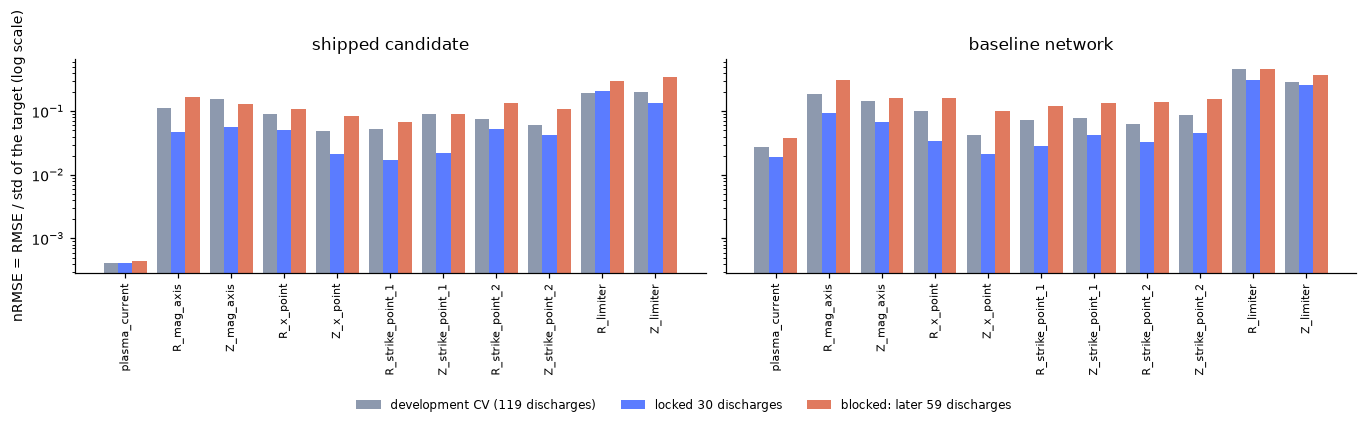


Protocol: nRMSE pooled over the rows of each test set; clean inputs; one seed; the three test sets are different discharges (see the tables above).


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
xs = np.arange(len(F.HEADLINE)); w = 0.27
for ax, r, title in zip(axes, ("cand", "base"), ("shipped candidate", "baseline network")):
    ax.bar(xs - w, [D[r]["clean"][t]["nrmse"] for t in F.HEADLINE], w, label="development CV (119 discharges)", color="#8d99ae")
    ax.bar(xs, [L[r]["clean"][t]["nrmse"] for t in F.HEADLINE], w, label="locked 30 discharges", color="#5b7cff")
    ax.bar(xs + w, [B[r][t]["nrmse"] for t in F.HEADLINE], w, label="blocked: later 59 discharges", color="#e07a5f")
    ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(F.HEADLINE, rotation=90, fontsize=7); ax.set_title(title)
axes[0].set_ylabel("nRMSE = RMSE / std of the target (log scale)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()
proto("nRMSE pooled over the rows of each test set; clean inputs; one seed; the three test sets are different discharges (see the tables above).")

## 6. Does the ordering survive another seed? The five-seed check

One seed per model is a weakness of the tables above. `results/ipp1-final-seeds.md` retrains the baseline and the candidate with four more seeds on the
same 119 discharges and scores them once on the same 30 (no recipe change); seed 0 is the model above. The table is read from that stored report.

In [9]:
txt = (RES / "ipp1-final-seeds.md").read_text()
pat = re.compile(r"\| (\w+) \((\w+)\) \| ([\d.e+-]+) \(([\d.e+-]+)\) \| ([\d.e+-]+) \(([\d.e+-]+)\) \| ([\d.]+) \| ([\d.]+) to ([\d.]+) \| (\d) of (\d) \| ([\d.]+) \|")
rows = []
for line in txt.splitlines():
    m = pat.match(line)
    if m:
        t, u, bm, bs, cm, cs, ratio, rlo, rhi, k, n, worst = m.groups()
        rows.append(dict(target=t, unit=u, base_mean=float(bm), base_sd=float(bs), cand_mean=float(cm), cand_sd=float(cs), ratio_of_means=float(ratio),
                         paired_ratio_min=float(rlo), paired_ratio_max=float(rhi), cand_better_in=f"{k} of {n}", worst_cand_over_best_base=float(worst)))
seeds = pd.DataFrame(rows).set_index("target")
assert len(seeds) == 7, "the seed report changed format"
print(seeds.to_string())
# seed 0 of the seed check is the model of this notebook: the numbers must agree
for t in ("R_mag_axis", "Z_limiter"):
    r0 = L["cand"]["clean"][t]["mae"] / L["base"]["clean"][t]["mae"]
    inside = seeds.loc[t, "paired_ratio_min"] <= r0 <= seeds.loc[t, "paired_ratio_max"]
    print(f"seed 0 of this notebook, {t}: ratio {r0:.2f}, inside the range of the five seeds [{seeds.loc[t, 'paired_ratio_min']:.2f}, {seeds.loc[t, 'paired_ratio_max']:.2f}]: {inside}")
KEY["seeds"] = {t: {"base": [seeds.loc[t, "base_mean"], seeds.loc[t, "base_sd"]], "cand": [seeds.loc[t, "cand_mean"], seeds.loc[t, "cand_sd"]],
                    "ratio": seeds.loc[t, "ratio_of_means"], "worst_over_best": seeds.loc[t, "worst_cand_over_best_base"]} for t in seeds.index}
proto("5 seeds (0 to 4) per recipe, each trained on the 119 development discharges and scored on the 30 locked discharges, clean inputs; mean and SD (n-1) over seeds; read from results/ipp1-final-seeds.md.")

                 unit  base_mean  base_sd  cand_mean  cand_sd  ratio_of_means  paired_ratio_min  paired_ratio_max cand_better_in  worst_cand_over_best_base
target                                                                                                                                                     
R_mag_axis         mm      0.289    0.011     0.1330   0.0060            0.46              0.43              0.50         5 of 5                       0.50
Z_mag_axis         mm      0.330    0.021     0.1920   0.0160            0.58              0.54              0.67         5 of 5                       0.67
R_x_point          mm      0.141    0.015     0.1110   0.0066            0.79              0.71              0.96         5 of 5                       0.97
R_strike_point_2   mm      0.206    0.013     0.1160   0.0150            0.56              0.49              0.68         5 of 5                       0.72
R_limiter          mm     10.800    0.350     4.6800   0.3200   

The candidate is better in every seed for all seven targets, and its worst seed is below the baseline's best seed everywhere. Seed noise is 3 to 13 % of the
value, small against the gains of 40 to 60 % on the axis, strike point and limiter point. The X point radius is the weak case: the gain is 21 %, and the
worst candidate seed is only 3 % below the best baseline seed. The plasma current of the candidate has SD 0 because it comes from a ridge regression,
which has no seed. Seed noise does not include the choice of the 30 discharges; that is the bootstrap of Section 2.

## 7. Noisy inputs: a different model

On the organizers' noisy file (white noise of about 0.155 of the input spread for the coils and 0.09 for the flux loops, no measurable drift; the drift
tests in `results/ipp1-robustness-findings.md` use our own synthetic model) the shipped candidate **fails**, because the neighbouring-coil differences amplify
the noise. The model to use for noisy inputs is the baseline network trained with noise and drift added (`base_aug`). The columns below: the clean-trained models
on the noisy test inputs, and the noise-trained model on clean and on noisy inputs.

In [10]:
cols = ["plasma_current", "R_mag_axis", "Z_mag_axis", "R_x_point", "R_limiter", "Z_limiter"]
spec = [("baseline (trained clean), clean inputs", "base", "clean"), ("baseline (trained clean), NOISY inputs", "base", "noisy"),
        ("shipped candidate (trained clean), NOISY inputs", "cand", "noisy"),
        ("noise-trained baseline, clean inputs", "base_aug", "clean"), ("noise-trained baseline, NOISY inputs", "base_aug", "noisy")]
noisy = pd.DataFrame({name: {t: L[r][c][t]["mae"] for t in cols} for name, r, c in spec}).T
noisy.columns = [f"{t} ({F.UNIT[t][1]})" for t in cols]
print(noisy.round(3).to_string())
dn = {name: {t: D[r][c][t]["mae"] for t in cols} for name, r, c in spec if r != "cand"}
print("\nsame models on the development cross-validation (119 discharges, out of fold):")
d2 = pd.DataFrame(dn).T; d2.columns = noisy.columns; print(d2.round(3).to_string())
KEY["noisy_locked"] = {name: {t: round(v, 3) for t, v in noisy.loc[name].items()} for name in noisy.index}
proto("locked: trained once on the 119 development discharges, tested on the 30; clean = equil_data.csv inputs, NOISY = the provided equil_data_noisy.csv inputs of the same rows; one seed; the noise-trained model sees noise 0.15 and drift 0.15 of each input's SD in training.")

                                                 plasma_current (kA)  R_mag_axis (mm)  Z_mag_axis (mm)  R_x_point (mm)  R_limiter (mm)  Z_limiter (mm)
baseline (trained clean), clean inputs                         1.199            0.307            0.321           0.161          10.621          22.479
baseline (trained clean), NOISY inputs                         5.626            9.156            3.823           4.348          48.883          62.265
shipped candidate (trained clean), NOISY inputs                4.311          189.877          205.936          47.170        1313.329         993.512
noise-trained baseline, clean inputs                           1.906            1.560            0.837           1.556          18.639          25.730
noise-trained baseline, NOISY inputs                           4.654            2.381            1.861           2.473          25.803          38.894

same models on the development cross-validation (119 discharges, out of fold):
              

Noise-trained models give up accuracy on clean inputs (see the first and fourth row), so the shipped pair needs to know which kind of input it gets;
no single model wins in both cases. The plasma current is the exception: the ridge regression of the candidate, trained on clean inputs, still gives 4.31 kA on the noisy inputs
against 4.65 kA for the noise-trained network. Taking the current from that ridge and everything else from the noise-trained network was not run as one recipe.

## 8. Latency of the shipped pair

Timing, not accuracy: random weights of the trained shapes, one sample, from the 24 raw inputs to the 16 outputs (`analysis/ipp1_latency.py --shipped`).
The table is read from the stored report `results/ipp1-latency-shipped.md`.

In [11]:
lt = (RES / "ipp1-latency-shipped.md").read_text()
hdr = re.search(r"CPU: ([^(]+)\((\d+) logical cores\).*?at the start (\[[^\]]+\]), at the end (\[[^\]]+\])", lt, re.S)
print(f"CPU: {hdr.group(1).strip()} ({hdr.group(2)} logical cores); load average (1, 5, 15 min) at the start {hdr.group(3)}, at the end {hdr.group(4)}")
rowpat = re.compile(r"\| (\w+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \|")
lat = pd.DataFrame([dict(path=m.group(1), median_ms=float(m.group(2)), p99_ms=float(m.group(3))) for m in map(rowpat.match, lt.splitlines()) if m]).set_index("path")
lat = lat.loc[["numpy_end_to_end_diverted", "numpy_end_to_end_limited", "ipp1_final_predict_diverted", "ipp1_final_predict_limited", "mps_end_to_end_limited_with_transfers"]]
base_lat = [m for m in map(rowpat.match, (RES / "ipp1-latency.md").read_text().splitlines()) if m and m.group(1) == "cpu_1_thread_single_sample"][0]
print(lat.to_string())
print(f"\nbaseline 24-16 network alone (results/ipp1-latency.md): median {float(base_lat.group(2)):.4f} ms, p99 {float(base_lat.group(3)):.4f} ms")
KEY["latency_ms"] = {k: [lat.loc[k, "median_ms"], lat.loc[k, "p99_ms"]] for k in lat.index}
KEY["latency_baseline_ms"] = [float(base_lat.group(2)), float(base_lat.group(3))]
proto("one sample, one CPU core (numpy) or the Apple GPU with its copies; 5,000 timed calls per row after warm-up; machine busy (load average 6 to 7), so the p99 is pessimistic and not a bound.")

CPU: Apple M5 (10 logical cores); load average (1, 5, 15 min) at the start [7.01, 6.47, 8.13], at the end [6.68, 6.42, 8.1]
                                       median_ms  p99_ms
path                                                    
numpy_end_to_end_diverted                 0.0154  0.0571
numpy_end_to_end_limited                  0.0274  0.0930
ipp1_final_predict_diverted               0.0260  0.0650
ipp1_final_predict_limited                0.0544  0.1883
mps_end_to_end_limited_with_transfers     0.9837  2.4127

baseline 24-16 network alone (results/ipp1-latency.md): median 0.0145 ms, p99 0.0209 ms

Protocol: one sample, one CPU core (numpy) or the Apple GPU with its copies; 5,000 timed calls per row after warm-up; machine busy (load average 6 to 7), so the p99 is pessimistic and not a bound.


The numpy path is the whole per-sample computation: 22 coil differences, standardisation, the general network, the ridge, the gate, (limited case only)
the limiter network and de-standardisation. It does not include collecting and integrating the coil signals, the noise-trained model needed for noisy
inputs, or any real-time operating system.

## 9. Key numbers (read by the conclusions below)

In [12]:
print("KEY_JSON", json.dumps(KEY))

KEY_JSON {"locked_discharges": 30, "locked_rows": 8761, "positive_polarity": {"development": 14, "locked": 2}, "locked_mae_cand": {"plasma_current": 0.0347, "R_mag_axis": 0.1331, "Z_mag_axis": 0.1721, "R_x_point": 0.1153, "Z_x_point": 0.0969, "R_strike_point_1": 0.108, "Z_strike_point_1": 0.0459, "R_strike_point_2": 0.1356, "Z_strike_point_2": 0.0264, "R_limiter": 4.5488, "Z_limiter": 8.3479}, "locked_mae_base": {"plasma_current": 1.1986, "R_mag_axis": 0.3067, "Z_mag_axis": 0.3213, "R_x_point": 0.161, "Z_x_point": 0.1617, "R_strike_point_1": 0.2121, "Z_strike_point_1": 0.0986, "R_strike_point_2": 0.212, "Z_strike_point_2": 0.0454, "R_limiter": 10.6206, "Z_limiter": 22.4793}, "is_limited_accuracy_locked": {"cand": 0.9916, "base": 0.9892}, "max_rel_diff_to_report_pct": 0.32, "bootstrap_ratio": {"plasma_current": [0.03, 0.02, 0.03], "R_mag_axis": [0.43, 0.38, 0.49], "Z_mag_axis": [0.54, 0.47, 0.6], "R_x_point": [0.72, 0.53, 0.97], "Z_x_point": [0.6, 0.49, 0.71], "R_strike_point_1": [0.51,

## Conclusions

- **Setup.** 30 discharges (8,761 rows) set aside before the final choice among four recipes, 119 development discharges (34,211 rows) for training; every model trained on whole discharges, the locked 30 scored once, pooled over rows. The notebook trains nothing: it recomputes all metrics from the cached predictions and compares 32 MAE values with `results/ipp1-final.md` (on the machine that made the report: no difference beyond its rounding; on another machine the retrained networks differ by about the seed noise).
- **Accuracy on the 30 discharges.** Shipped candidate, mean absolute error, one seed: `R_mag_axis` 0.133 mm (95 % bootstrap interval 0.099 to 0.177), `Z_mag_axis` 0.172 mm, `R_x_point` 0.115 mm, `R_strike_point_2` 0.136 mm, `R_limiter` 4.5 mm, `Z_limiter` 8.3 mm, plasma current 0.035 kA, `is_limited` accuracy 99.2 %. The baseline network has 0.307, 0.321, 0.161, 0.212, 10.6, 22.5 mm and 1.20 kA. The ratio interval excludes 1 for all 11 headline targets; the weakest are `R_x_point` (0.72, interval 0.53 to 0.97) and `R_strike_point_2` (0.64, 0.43 to 0.94). The plasma current is the ridge regression, not the network (linear model about 43 times better than the network, `results/ipp1-baseline.md`).
- **Quote it with the cross-validation next to it.** On the 119 development discharges the same recipes give `R_mag_axis` 0.230 mm (candidate) and 0.479 mm (baseline) in 5-fold cross-validation by discharge. The locked set is easier: the mean relative error over the 16 targets is 35 % lower for both recipes (0.0590 against 0.0912 and 0.0803 against 0.1228), the radial axis error 42 % and 36 % lower. The easing is concentrated in the axis, X point and strike points; plasma current and `R_limiter` are not easier. Only 2 of the 30 discharges have the reversed plasma current (6.7 %, against 14 of 119 in development), and such discharges carry most of the squared axis error in `results/ipp1-distribution.md`. A headline of about 0.2 mm on the radial axis is more honest than 0.13 mm.
- **"Nobody saw them" is too strong.** The 30 discharges were set aside before the final choice among four recipes and no recipe was changed after the locked numbers were seen, but the ideas behind the recipe (differences of neighbouring coils, Huber loss, the limiter network) were tried on cross-validation over all 149 discharges, which include these 30. Say "30 discharges set aside before the final model choice".
- **Later campaigns are harder.** Trained on the lower half of the development discharge numbers and tested on the upper half (59 discharges), the candidate's radial axis error is 0.397 mm against 0.216 mm for random folds on the same discharges, and 1.07 to 2.83 times higher across the headline targets (baseline: 1.231 against 0.448 mm). Part of the gap is the smaller training set (about 60 instead of 95 discharges), so this is an upper bound on drift between campaigns, not a measurement of it.
- **The ordering survives other seeds.** With five seeds per recipe the candidate is better in every seed for all seven checked targets and its worst seed is below the baseline's best seed everywhere. Seed noise is 3 to 13 %; the gain is 40 to 60 % on the axis, strike point and limiter point. `R_x_point` is the weak case (gain 21 %, worst candidate seed only 3 % below the best baseline seed). The candidate's current error has SD 0 because it is a ridge regression.
- **Noisy inputs need another model.** On the organizers' noisy file (white noise, no measurable drift) the shipped candidate fails (`R_mag_axis` 190 mm) because the differences of neighbouring coils amplify the noise. The model to use there is the baseline network trained with noise and drift added: on the 30 discharges `R_mag_axis` 2.38 mm, `Z_mag_axis` 1.86 mm, limiter 25.8 and 38.9 mm, plasma current 4.65 kA. It gives up accuracy on clean inputs (`R_mag_axis` 1.56 mm against 0.307 mm), so the shipped pair needs to know which kind of input it gets. The ridge for the current keeps 4.31 kA on the noisy inputs; the combination of that ridge with the noise-trained network was not run. The drift tests use our own synthetic drift, not a measured one.
- **Latency of the shipped pair.** From the 24 raw inputs to the 16 outputs in numpy on one core of an Apple M5: median 0.0154 ms (diverted, general network only) and 0.0274 ms (limited, both networks), p99 0.057 and 0.093 ms, against 0.0145 ms for the baseline network alone; the GPU needs 0.98 ms per sample. The machine was busy (load average 6 to 7), so the p99 is pessimistic and no bound. Collecting and integrating the coil signals is not included.
- **What this notebook does not show.** Discharges of a new kind (see `results/ipp1-unusual-shapes.md`: 1.2 to 2.4 times larger error when a whole family of shapes is left out), the end of the discharge, which is worse than the middle for all recipes (`results/ipp1-final.md`), and the camera.